# 01 - Data Visualization and Audit

Milestone 1: 5 figures + statistical tests on the Rakuten dataset.


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from IPython import display
from src.data_utils import load_merged_data, get_image_path

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Environment and data_utils loaded successfully.")


Environment and data_utils loaded successfully.


## 1. Load Data
Using `load_merged_data()` from `src/data_utils.py`.


In [ ]:
df = load_merged_data()

# Data structure
print("Dataset Shape",df.shape)
df.head(8)

Dataset Shape (84916, 5)

Missing values per column:
 designation        0
description    29800
productid          0
imageid            0
prdtypecode        0
dtype: int64


,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,2705
5,Afrique Contemporaine N° 212 Hiver 2004 - Doss...,NaN,5862738,393356830,2280
6,Christof E: Bildungsprozessen Auf Der Spur,NaN,91920807,907794536,10
7,Conquérant Sept Cahier Couverture Polypro 240 ...,CONQUERANT CLASSIQUE Cahier 240 x 320 mm seyès...,344240059,999581347,2522


## 2. Data Audit & Missing Values

In [67]:
print("\nData info:\n")
df.info()

print("\nTotal Categories:", df["prdtypecode"].nunique())
# There are about 27 differnt categories to classify

print("\nMissing values per column:\n", df.isna().sum())
# The description has a large volume of missing values


Data info:

<class 'pandas.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   designation  84916 non-null  str  
 1   description  55116 non-null  str  
 2   productid    84916 non-null  int64
 3   imageid      84916 non-null  int64
 4   prdtypecode  84916 non-null  int64
dtypes: int64(3), str(2)
memory usage: 52.5 MB

Total Categories: 27

Missing values per column:
 designation        0
description    29800
productid          0
imageid            0
prdtypecode        0
dtype: int64


## 3. Figure 1: Class Distribution

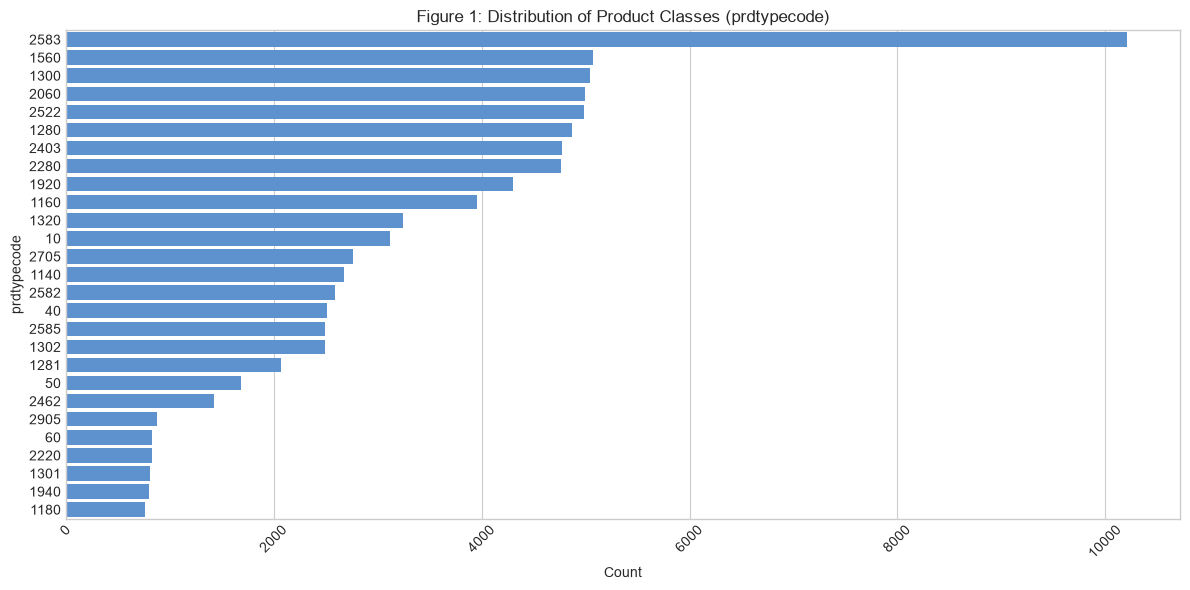

Top Class (2583): 10209 samples
Bottom Class (1180): 764 samples
Imbalance Ratio: 13.36x
Chi-Square Stat: 36570.33, p-value: 0.0000e+00


In [ ]:

order = df['prdtypecode'].value_counts().index

plt.figure(figsize=(12, 6))
sns.countplot(y="prdtypecode", data=df, color='#4A90E2', order = order)
plt.title("Figure 1: Distribution of Product Classes (prdtypecode)")
plt.ylabel("prdtypecode")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Statistical validation: Chi-Square Goodness-of-Fit against uniform distribution
counts = df['prdtypecode'].value_counts()
chi2_stat, p_val_chi2 = stats.chisquare(counts)
imbalance_ratio = counts.iloc[0] / counts.iloc[-1]

print(f"Top Class ({counts.index[0]}): {counts.iloc[0]} samples")
print(f"Bottom Class ({counts.index[-1]}): {counts.iloc[-1]} samples")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}x")
print(f"Chi-Square Stat: {chi2_stat:.2f}, p-value: {p_val_chi2:.4e}")

# Seems to have a lot of disparity between the product type samples, around 10000 max count to around 800 miniumum count.or
# This shows skewed distribution indication that some of the product types are mass marketed by the sellers as compared to others
# We should consider this for our model a it may misclasisfy based on the most common product classes?
# p-value which is below the $0.05 threshold indicates the probability that this imbalance did not occur by random sampling
# Hoe do we weight for the class of products which have low count

## 4. Figure 2: Missing Description Rate by Class

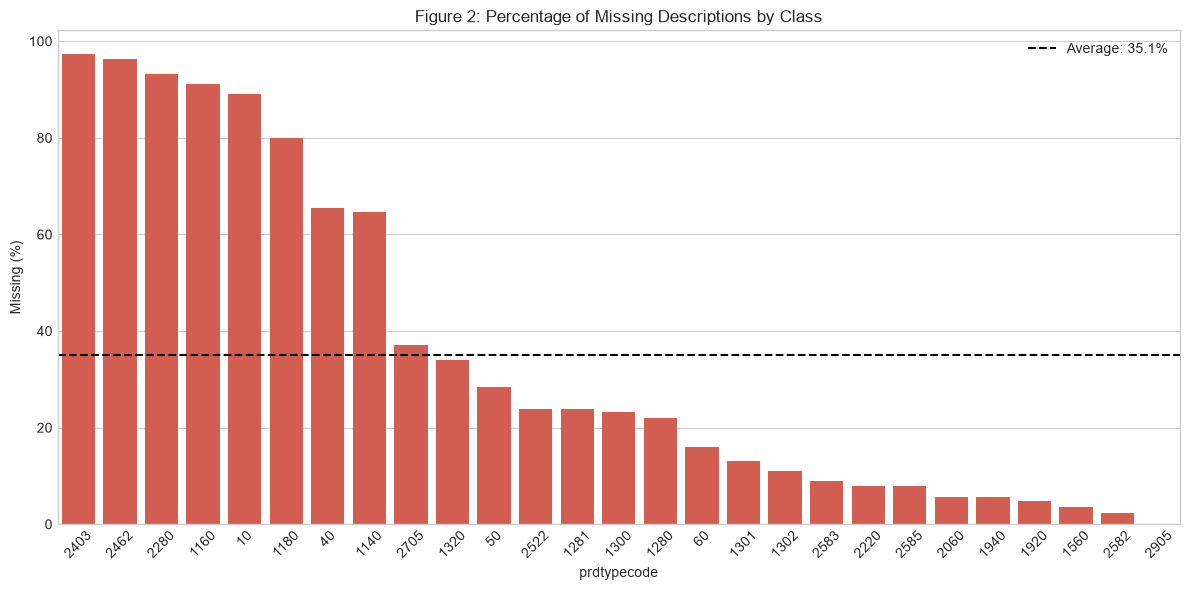

In [ ]:
df['missing_desc'] = df['description'].isnull()
missing_by_class = (df.groupby('prdtypecode')['missing_desc'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_by_class.index.astype(str), y=missing_by_class.values, color='#E74C3C')
plt.axhline(df['missing_desc'].mean() * 100, color='black', linestyle='--', label=f"Average: {df['missing_desc'].mean()*100:.1f}%")
plt.title("Figure 2: Percentage of Missing Descriptions by Class")
plt.xlabel("prdtypecode")
plt.ylabel("Missing (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Missing descriptions are also skewed, some categoreis have no descroption at all
# If some products requires more descriotion e.g. maybe techincla description, they will anturally be more, might indictae certain class of products?
# However it may not be enough to classify a product type 
# what should we do with missing description products?



## 5. Statistical Test: Chi-Squared Test

In [6]:
table = pd.crosstab(df['prdtypecode'], df['missing_desc'])
chi2, p_val, dof, _ = stats.chi2_contingency(table)
print(f"Chi-square: {chi2:.2f}, p-value: {p_val:.2e}")


Chi-square: 43757.77, p-value: 0.00e+00


## 6. Figure 3 & 4: Text Length Distributions

In [ ]:
# 1. Top 5 categories
top_5 = df["prdtypecode"].value_counts().head(5).index
subset_df = df[df["prdtypecode"].isin(top_5)].copy()
subset_df["title_len"] = subset_df["designation"].astype(str).str.len()

# 2. Plot Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=subset_df, x="prdtypecode", y="title_len", palette="Set2")
plt.title("Title Character Length Distribution (Top 5 Categories)")
plt.xlabel("Category Code")
plt.ylabel("Character Count")
plt.tight_layout()
plt.show()

# 3. Extract Quartiles & Kruskal-Wallis Test
quartiles = subset_df.groupby("prdtypecode")["title_len"].agg(
    Q1=lambda s: s.quantile(0.25),
    Median="median",
    Q3=lambda s: s.quantile(0.75),
    IQR=lambda s: s.quantile(0.75) - s.quantile(0.25)
)
print("Quartile Breakdown:\n", quartiles)

kw_groups = [grp["title_len"].values for _, grp in subset_df.groupby("prdtypecode")]
h_stat, p_val_kw = stats.kruskal(*kw_groups)
print(f"Kruskal-Wallis Test: H={h_stat:.2f}, p-value: {p_val_kw:.4e}")


/var/folders/97/2gvgrl2j75b6f606jm0s1scc0000gn/T/ipykernel_53293/274037852.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset_df, x='prdtypecode', y='designation', palette='Set2')
/var/folders/97/2gvgrl2j75b6f606jm0s1scc0000gn/T/ipykernel_53293/274037852.py:11: UserWarning: Glyph 146 (\x92) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/97/2gvgrl2j75b6f606jm0s1scc0000gn/T/ipykernel_53293/274037852.py:11: UserWarning: Glyph 150 (\x96) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/97/2gvgrl2j75b6f606jm0s1scc0000gn/T/ipykernel_53293/274037852.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
/Users/wahajaslam/capstone_raukaten/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:15

## 7. Figure 5: Image Dimensions & Aspect Ratio Validation


In [75]:
from src.data_utils import load_image

# 1. Sample 1000 images to inspect dimensions
img_sample = df.sample(n=min(1000, len(df)), random_state=42)

dims = []
for _, row in img_sample.iterrows():
    im = load_image(row["imageid"], row["productid"])
    w, h = im.size
    dims.append({"width": w, "height": h, "aspect_ratio": round(w / h, 3), "prdtypecode": row["prdtypecode"]})

dim_df = pd.DataFrame(dims)

# 2. Scatter plot of width vs height
plt.figure(figsize=(8, 6))
sns.scatterplot(data=dim_df, x="width", y="height", alpha=0.5, color="teal")
plt.plot([0, 500], [0, 500], color="red", linestyle="--", label="1:1 Square Ratio")
plt.title("Figure 5: Image Dimensions (Width vs. Height)")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Validation: Non-square percentage & KS-Test
non_sq_pct = (dim_df["aspect_ratio"] != 1.0).mean() * 100
top_two = dim_df["prdtypecode"].value_counts().head(2).index
ks_stat, p_val_ks = stats.ks_2samp(
    dim_df[dim_df["prdtypecode"] == top_two[0]]["aspect_ratio"],
    dim_df[dim_df["prdtypecode"] == top_two[1]]["aspect_ratio"]
)
print(f"Non-Square Proportion: {non_sq_pct:.1f}%")
print(f"KS-Test: stat={ks_stat:.2f}, p-value: {p_val_ks:.4e}")


ValueError: Could not interpret value `width` for `x`. An entry with this name does not appear in `data`.

<Figure size 800x600 with 0 Axes>

## 8. Figure 6: Manifold Learning (Isomap)

We use Isomap to identify variance factors in the images. Manifold learning allows us to identify variance factors and may eventually help us create new features that are more informative than the raw features in the dataset.

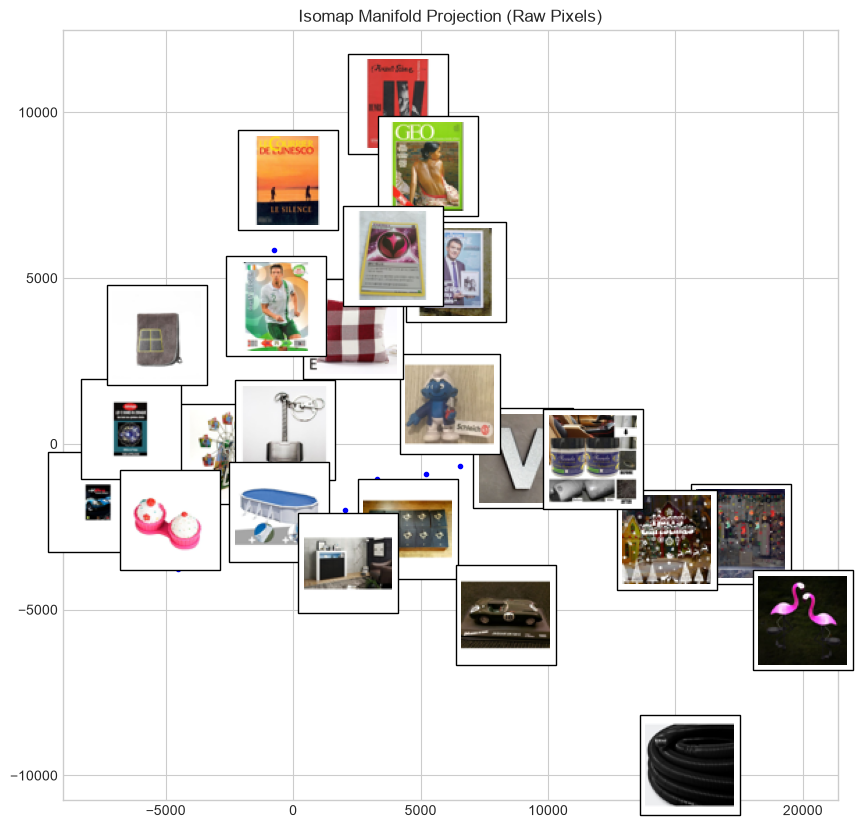

In [ ]:
from sklearn.manifold import Isomap
from src.vision_utils import plot_components

# Sample images and prepare data (using 64x64 to preserve square aspect ratio)
sample = df.sample(100, random_state=42)
img_gray = []
img_rgb = []
for _, row in sample.iterrows():
    path = get_image_path(row["imageid"], row["productid"])
    img = Image.open(path).resize((64, 64))
    img_gray.append(np.array(img.convert("L")))
    img_rgb.append(np.array(img.convert("RGB")))

# Flatten grayscale images for Isomap
data = np.array(img_gray).reshape(len(img_gray), -1)

# Plot components
fig, ax = plt.subplots(figsize=(10, 10))

plot_components(data,
                model=Isomap(n_components=2),
                images=np.array(img_rgb),
                thumb_frac=0.08)

plt.title("Isomap Manifold Projection (Raw Pixels)")
plt.show()
